# Preprocessing and Logistic Regression Baseline

## 1. Data Preparation: Understanding One Image

### Purpose and Scope

This notebook covers **Person 2: preprocessing and the logistic regression baseline** for the group's fruit and vegetable classification project.

We build on Jessika's EDA, which uses 2,003 images across nine target classes. Apple varieties share the label `apple`, and potato varieties share the label `potato`.

Our planned deliverables are a shared image preprocessing function, a logistic regression baseline, and a shared evaluation function for accuracy, macro-F1, and a confusion matrix. These will use the group's agreed labels and shared dataset split.

We start by working through one image before writing the reusable function. Each subsection explains its purpose, introduces the Python terms, runs a short cell, and interprets the output, following Jessika's notebook structure.

**Workflow:** open an image as RGB → resize it → inspect its numbers → normalize the numbers → arrange them into one feature row.

The image size used here is a starting example for the baseline, not a final choice for every model. The shared dataset split, baseline training, and evaluation come later.

### 1.1 Load One Image as RGB

We start with one Fuji apple image. The path is relative to `data/raw_images`, so you can replace `example_file` with another included image.

RGB stores three color channels: red, green, and blue. Keeping color is useful because Jessika's EDA showed that color varies both between foods and within the apple class.

#### Python Glossary – Loading and Labels

- `Path.cwd()` gives the folder where Python is running. `.parent` moves one folder up if we are running from `notebooks`.
- `/` joins folder and file names into a path.
- `class_mapping` is a dictionary linking original variety labels to broader food labels.
- `.get(original_class, original_class)` uses the mapped label when available, otherwise it keeps the original label.
- `with Image.open(...)` opens the file and closes it when the block finishes.
- `.convert("RGB")` creates an image with red, green, and blue channels.
- `.copy()` makes a separate image for the small preview.

The preview below is smaller for display. `rgb_image` still holds the full-resolution RGB image.

Image: fuji_apple/fuji_apple_001.jpg
Original label: fuji_apple
Target label: apple
Full image size (width, height): (1024, 768)
Color mode: RGB


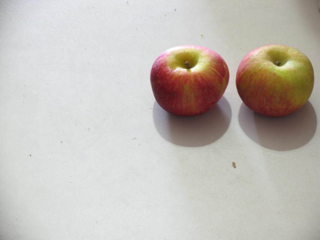

In [1]:
from pathlib import Path
import numpy as np
from PIL import Image
from IPython.display import display

project_folder = Path.cwd()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent

data_folder = project_folder / "data" / "raw_images"
example_file = "fuji_apple/fuji_apple_001.jpg"
example_path = data_folder / example_file

class_mapping = {
    "fuji_apple": "apple",
    "granny_smith_apple": "apple",
    "agata_potato": "potato",
    "asterix_potato": "potato"
}

original_class = example_path.parent.name
target_class = class_mapping.get(original_class, original_class)

with Image.open(example_path) as image:
    rgb_image = image.convert("RGB")

print("Image:", example_file)
print("Original label:", original_class)
print("Target label:", target_class)
print("Full image size (width, height):", rgb_image.size)
print("Color mode:", rgb_image.mode)

original_preview = rgb_image.copy()
original_preview.thumbnail((320, 240))
display(original_preview)

#### 1.1.1 Loading and Labels – Findings

The example uses the original folder label `fuji_apple` and the target label `apple`. Other Fuji or Granny Smith images would use the same target label under this mapping.

The displayed preview is smaller than the full image. The printed size refers to the full image, not the preview.

**Scope:** This cell is for an included example image. It does not build the full nine-class dataset or check the exclusion list. Use an image from one of the included folders when editing `example_file`. Later, the shared data loader should use the labels and files agreed in the group split.

### 1.2 Resize the Image for a Small Baseline

The original 1024 × 768 RGB image contains **2,359,296 channel values**. That is a large number of inputs compared with our 2,003 images.

For this walkthrough, we try **64 pixels wide and 48 pixels high**. Both sizes have the same 4:3 proportions, so this choice preserves the shape of these dataset images.

This reduces the number of inputs, but also loses fine details. We need validation results before deciding whether this resolution is sufficient.

#### Python Glossary – Resizing

- `image_width` and `image_height` are settings you can change.
- `.resize((width, height), ...)` creates an image with the requested size.
- `Image.Resampling.LANCZOS` is a resizing method that combines nearby pixel information when reducing the image.
- Pillow expects **width first, then height**.

The output below shows the actual small image. Keep a 4:3 ratio, such as 128 × 96, if you want to try another size without stretching these images.

Original size (width, height): (1024, 768)
Resized size (width, height): (64, 48)


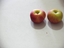

In [2]:
image_width = 64
image_height = 48

resized_image = rgb_image.resize(
    (image_width, image_height),
    Image.Resampling.LANCZOS
)

print("Original size (width, height):", rgb_image.size)
print("Resized size (width, height):", resized_image.size)
display(resized_image)

#### 1.2.1 Resizing – Findings

The resized image has fewer pixels while retaining the original proportions. Its smaller dimensions make the next numerical steps easier to inspect.

Resizing does not remove the background or bring the food closer. If the food occupies a small area in the original, it will still occupy a small area after resizing. That is one reason to inspect model performance before choosing further preprocessing.

### 1.3 Inspect the Image as Numbers

Machine learning models work with numbers. NumPy converts the resized image into an **array**, a structure that stores those numbers in an organized shape.

For an RGB image, the array shape is `(height, width, channels)`. This order differs from Pillow's `(width, height)` size.

#### Python Glossary – Pixel Arrays

- `np.asarray(resized_image)` reads the image as a NumPy array.
- `.shape` reports the array dimensions.
- `.dtype` reports the number type. `uint8` stores whole numbers from 0 to 255.
- `[0, 0]` selects the first row and first column: the top-left pixel. Its three values are red, green, and blue.
- `.min()` and `.max()` show the smallest and largest values present in this particular image.
- `.size` counts all channel values in the array.

The top-left pixel may belong to the background, so it is only an example of the numerical representation.

In [3]:
pixel_values = np.asarray(resized_image)

print("Array shape (height, width, channels):", pixel_values.shape)
print("Number type:", pixel_values.dtype)
print("Top-left pixel [red, green, blue]:", pixel_values[0, 0])
print("Smallest value in this image:", pixel_values.min())
print("Largest value in this image:", pixel_values.max())
print("Total channel values:", pixel_values.size)

Array shape (height, width, channels): (48, 64, 3)
Number type: uint8
Top-left pixel [red, green, blue]: [168 169 171]
Smallest value in this image: 0
Largest value in this image: 250
Total channel values: 9216


#### 1.3.1 Pixel Arrays – Findings

With the default settings, the array shape is `(48, 64, 3)`: 48 rows, 64 columns, and three color channels. There are **9,216 channel values** in total.

The observed minimum and maximum do not have to be exactly 0 and 255. Those are the allowed limits, while the printed values show what is present in this image.

### 1.4 Normalize Pixel Values to a 0–1 Scale

We divide the pixel values by 255. For example, 0 becomes 0, 255 becomes 1, and 128 becomes approximately 0.502.

This gives the model inputs on a consistent numerical scale. It does not fix uneven lighting, blur, or background differences.

#### Python Glossary – Normalization

- `.astype("float32")` converts whole numbers into decimal numbers.
- `/ 255.0` changes the scale from 0–255 to 0–1.
- `normalized_pixels` keeps the result separate from the original pixel array.

This fixed conversion does not learn any statistics from the dataset. If we later use a fitted scaler or PCA, those steps must learn from training data only. Pretrained models may require their own normalization rules.

In [4]:
normalized_pixels = pixel_values.astype("float32") / 255.0

print("Number type after normalization:", normalized_pixels.dtype)
print("Array shape:", normalized_pixels.shape)
print("Top-left pixel before:", pixel_values[0, 0])
print("Top-left pixel after:", normalized_pixels[0, 0])
print("Smallest normalized value:", normalized_pixels.min())
print("Largest normalized value:", normalized_pixels.max())

Number type after normalization: float32
Array shape: (48, 64, 3)
Top-left pixel before: [168 169 171]
Top-left pixel after: [0.65882355 0.6627451  0.67058825]
Smallest normalized value: 0.0
Largest normalized value: 0.98039216


#### 1.4.1 Normalization – Findings

The shape stays the same, while the values become decimal numbers between 0 and 1. The relative pixel intensities are retained on a different scale.

The maximum present in an image will only become 1 if that image contains a channel value of 255. We are using the fixed limit 255, not stretching each image by its own maximum.

### 1.5 Arrange the Values into One Feature Row

For logistic regression, we need a table where **each row is an image** and **each column is an input feature**. In this first representation, a feature is a pixel's red, green, or blue value at a particular position.

**Flattening** arranges the image array into a single sequence of values. We then give that sequence one row, ready to join with rows from other images later.

#### Python Glossary – Flattening

- `.reshape(-1)` arranges all values into one list-like array. `-1` asks NumPy to calculate its length.
- `.reshape(1, -1)` arranges the values into one row and calculates the number of columns.
- `[:12]` selects the first 12 values for a small preview.
- `np.round(..., 3)` displays values rounded to three decimal places; the feature row keeps its original precision.

Flattening retains the values in a consistent order, but logistic regression does not explicitly model neighboring pixels or learn visual patterns in the way a CNN does.

In [5]:
feature_vector = normalized_pixels.reshape(-1)
feature_row = feature_vector.reshape(1, -1)

print("Image array shape:", normalized_pixels.shape)
print("Flattened vector shape:", feature_vector.shape)
print("Feature table shape (images, features):", feature_row.shape)
print("Number of features per image:", feature_row.shape[1])
print("First 12 values:", np.round(feature_vector[:12], 3))
print("Target label for this row:", target_class)

Image array shape: (48, 64, 3)
Flattened vector shape: (9216,)
Feature table shape (images, features): (1, 9216)
Number of features per image: 9216
First 12 values: [0.659 0.663 0.671 0.706 0.71  0.725 0.745 0.749 0.769 0.773 0.776 0.8  ]
Target label for this row: apple


#### 1.5.1 Feature Row – Findings

With the default 64 × 48 RGB size, the result is **one row with 9,216 features**, with shape `(1, 9216)`.

Flattening changes how the numbers are arranged; it does not discard additional values. The earlier resizing step is what reduced the detail.

There are still many features compared with the number of images. This connects to the lecture's **curse of dimensionality**: having many inputs with relatively few examples can make learning reliable patterns difficult. A small resolution is a starting point; regularization and possibly PCA can be investigated when we build the baseline.

### 1.6 Preprocessing Walkthrough – Summary and Next Steps

| Stage | Representation with the default settings | Reason |
|---|---|---|
| RGB image | 1024 × 768 pixels, three channels | Keep the color information |
| Resized image | 64 × 48 pixels, three channels | Reduce the number of model inputs |
| Pixel array | `(48, 64, 3)`, whole numbers in 0–255 | Inspect the image numerically |
| Normalized array | `(48, 64, 3)`, decimal numbers in 0–1 | Use a consistent numerical scale |
| Feature row | `(1, 9216)` | Represent one image for logistic regression |

The measurements above describe one example. They do not establish which preprocessing settings give the best classification results.

**Settings to try:** Change `example_file` in 1.1, or `image_width` and `image_height` in 1.2, then rerun that cell and the cells below it. The summary table describes the default settings; update it if you choose different settings for the report.

**Next:** turn the understood steps into a small reusable function, then use the group's shared labels and `split.csv` for the baseline. Compare preprocessing choices using validation data and reserve the test data for final evaluation. The CNN can keep the image array shape rather than flattening it, and transfer learning may need a different size or normalization.

## 2. A Reusable Image Preprocessing Function

### Purpose

Section 1 showed each preprocessing step separately. The shared function now lives in [`src/preprocess.py`](../src/preprocess.py), where the group's notebooks and app can import the same implementation.

This notebook explains the choices and checks the output. The Python module contains the reusable code.

**Input:** an image path, plus the desired width and height.

**Output:** an RGB NumPy array of decimal values on a 0–1 scale, with shape `(height, width, 3)`.

We keep the image in its grid shape. For logistic regression, we flatten the returned array afterward. A CNN can use the grid. The 0–1 normalization is our baseline starting point; a pretrained model may require different preprocessing.

### 2.1 Import the Shared Function

#### Python Glossary – Importing from src

- `src` holds reusable Python source code. `preprocess.py` is a **module**: a Python file containing the function and its imports.
- `sys.path` is the list of folders Python searches when importing code.
- `str(project_folder)` turns the project path from Section 1 into text.
- `sys.path.insert(0, ...)` puts the project folder at the start of that search list. This lets Python find `src` when Jupyter runs from `notebooks`.
- `from src.preprocess import load_image` makes the function available in this notebook.

#### Python Glossary – Function Inputs and Output

Open `src/preprocess.py` to read or edit the definition:

- `def load_image(...):` defines the steps that run when we call the function.
- `image_path` is the file we want to open.
- `image_width=64` and `image_height=48` are default values, used when sizes are not supplied.
- Variables inside the function are local to the call, so they do not replace the walkthrough's variables.
- `return normalized_pixels` sends the prepared array back to the caller.

The function handles one image; class selection and labels remain separate.

In [6]:
import sys

if str(project_folder) not in sys.path:
    sys.path.insert(0, str(project_folder))

from src.preprocess import load_image

print("Imported load_image from src/preprocess.py")

Imported load_image from src/preprocess.py


#### 2.1.1 Shared Function Import – Findings

The import makes the function from `src/preprocess.py` available here. The next cell calls it using the same image and settings as the walkthrough.

The function resizes directly to the requested width and height. Our defaults match the dataset's 4:3 images. A different aspect ratio would be stretched; handling other image shapes is a later design choice for the app.

Other notebooks can use the same import after making the project folder available to Python. A script launched from the project root can use `from src.preprocess import load_image` directly.

### 2.2 Use the Function and Compare It with the Walkthrough

We pass in the same file and dimensions used in Section 1. This lets us check whether combining the steps changed the result.

#### Python Glossary – Calling and Checking

- `processed_image = load_image(...)` calls the function and stores its returned array.
- `image_width=image_width` passes the earlier width setting into the function's width parameter. The left side names the parameter; the right side is our existing variable.
- `np.allclose(first, second)` checks whether corresponding numbers in two arrays are equal within a small numerical tolerance.
- `True` in the comparison below means the function agrees with the individual steps for this example.
- `.reshape(1, -1)` makes one feature row after preprocessing, as in Section 1.

To use the default size directly in your own code, you can write `processed_image = load_image(example_path)`. Here we pass the dimensions explicitly so that changes to the Section 1 settings are respected.

In [7]:
processed_image = load_image(
    example_path,
    image_width=image_width,
    image_height=image_height
)

print("Array shape:", processed_image.shape)
print("Number type:", processed_image.dtype)
print("Smallest value:", processed_image.min())
print("Largest value:", processed_image.max())

matches_walkthrough = np.allclose(processed_image, normalized_pixels)
print("Matches the individual steps:", matches_walkthrough)

processed_feature_row = processed_image.reshape(1, -1)
print("Logistic regression feature row:", processed_feature_row.shape)

Array shape: (48, 64, 3)
Number type: float32
Smallest value: 0.0
Largest value: 0.98039216
Matches the individual steps: True
Logistic regression feature row: (1, 9216)


#### 2.2.1 Function Comparison – Findings

With the current 64 × 48 settings, the function returns a `(48, 64, 3)` array of `float32` values on the 0–1 scale. The comparison output reports whether it matches the walkthrough.

The flattened result has shape `(1, 9216)`. We can obtain that row from the returned array without putting flattening inside the function.

This checks consistency for one image, not model accuracy or performance across the full dataset.

### 2.3 Try a Different Image Size

We can reuse the function with another size by changing its inputs. We do not need to rewrite the image-processing steps.

The example below tries 128 × 96, preserving the same 4:3 proportions. Doubling both width and height gives four times as many pixels and features.

#### Python Glossary – Optional Settings

- `image_width=128` overrides the default width for this call.
- `image_height=96` overrides the default height for this call.
- `.size` counts all the channel values in the returned array. This is the number of inputs a flattened image would provide to logistic regression.

You can edit these two numbers and rerun this cell to inspect another size. The earlier `processed_image` remains available because we store this result in a different variable.

In [8]:
larger_image = load_image(
    example_path,
    image_width=128,
    image_height=96
)

print("Larger image array shape:", larger_image.shape)
print("Features after flattening:", larger_image.size)
print("Earlier example feature count:", processed_image.size)

Larger image array shape: (96, 128, 3)
Features after flattening: 36864
Earlier example feature count: 9216


#### 2.3.1 Alternative Size – Findings and Next Steps

The 128 × 96 example returns an array with shape `(96, 128, 3)` and 36,864 channel values. With the default settings in Section 1, the smaller image has 9,216 values.

A larger image keeps more detail from the original, but gives logistic regression more inputs to learn from. We need validation results to decide which size is useful; this example alone does not establish that a larger size is better.

**Next:** use the agreed class mapping and the group's shared `split.csv` to build image arrays and labels for the baseline. The same function can then prepare every selected image consistently. The preprocessing function is now shared through `src/preprocess.py`; the shared evaluation function will follow after we agree on that interface.

## 3. Cropping Experiment: Can We Reduce the Background?

### Purpose

Jessika's EDA and our visual inspection showed that some foods occupy only a small part of the image. When we resize the whole image, those foods can become very small.

We explore a simple question: **Can a background-color estimate help us draw a closer rectangle around the food before resizing?**

This is an exploratory comparison on three selected examples, not a measurement of model accuracy. We retain examples where the method struggles so that its limitations are visible.

**Workflow:** estimate background color from corners → flag pixels with different colors → draw a rectangle around them → add a margin → crop → resize for comparison.

### 3.1 Select Examples and Settings

We use an apple, a kiwi, and plums. These are selected examples, not a representative sample of all nine target classes.

#### Python Glossary – Experiment Settings

- `crop_example_files` lists paths relative to `data/raw_images`.
- `background_threshold` controls how different a pixel must be from the estimated background to be flagged. It is measured on the original 0–255 color scale.
- A lower threshold selects more pixels, including more background and shadows. A higher threshold selects fewer pixels and may miss parts of the food.
- `corner_size` is the width and height of each corner patch in original-image pixels.
- `crop_margin` adds space around the detected rectangle to reduce the chance of cutting too close to the food.

The threshold 50 is a starting experiment, not a validated rule. Edit these settings and rerun the cells below to explore their effects.

In [9]:
crop_example_files = [
    "fuji_apple/fuji_apple_001.jpg",
    "kiwi/kiwi_001.jpg",
    "plum/plum_001.jpg"
]

background_threshold = 50
corner_size = 40
crop_margin = 32

### 3.2 Estimate a Crop Rectangle

We assume the four image corners mostly show background. For each RGB channel, we take the median of those corner values as a typical background color. The median is the middle value after sorting.

We then compare every pixel with that color. If any of its three channels differs by more than the threshold, we mark the pixel as a possible foreground pixel.

**Important:** Different from background does not mean fruit. Shadows, uneven lighting, marks, and other objects can also be selected.

#### Python Glossary – Masks and Coordinates

- `np.asarray(image, dtype="float32")` gives decimal pixel values on the original 0–255 scale. Decimal storage lets us subtract colors without whole-number wraparound.
- `[:corner_size, :corner_size]` selects the top-left patch. Negative slices select patches at the bottom or right.
- `.reshape(-1, 3)` arranges patch pixels into rows of RGB values.
- `np.concatenate(...)` joins the four patch lists.
- `np.median(..., axis=0)` gives one median for each RGB channel.
- `np.abs(pixels - background_color)` measures the difference from the estimated color.
- `.max(axis=2)` selects the largest channel difference at each pixel.
- A **mask** is a grid of `True` and `False`: selected pixels are `True`.
- `np.where(mask)` returns the row and column positions of the selected pixels.
- The crop box is `(left, top, right, bottom)`. Pillow excludes the right and bottom coordinates, so we add 1 after the maximum selected coordinate.
- `max(0, ...)` and `min(image.width, ...)` keep the box within the image.

This helper stays in the notebook while we investigate it. It is not part of the shared baseline preprocessing yet.

In [10]:
def estimate_crop_box(image, threshold, corner_size, margin):
    pixels = np.asarray(image, dtype="float32")

    top_left = pixels[:corner_size, :corner_size]
    top_right = pixels[:corner_size, -corner_size:]
    bottom_left = pixels[-corner_size:, :corner_size]
    bottom_right = pixels[-corner_size:, -corner_size:]

    corner_pixels = np.concatenate([
        top_left.reshape(-1, 3),
        top_right.reshape(-1, 3),
        bottom_left.reshape(-1, 3),
        bottom_right.reshape(-1, 3)
    ])
    background_color = np.median(corner_pixels, axis=0)

    color_difference = np.abs(pixels - background_color)
    largest_difference = color_difference.max(axis=2)
    foreground_mask = largest_difference > threshold

    row_positions, column_positions = np.where(foreground_mask)

    if len(column_positions) == 0:
        crop_box = (0, 0, image.width, image.height)
    else:
        left = max(0, int(column_positions.min()) - margin)
        top = max(0, int(row_positions.min()) - margin)
        right = min(image.width, int(column_positions.max()) + 1 + margin)
        bottom = min(image.height, int(row_positions.max()) + 1 + margin)
        crop_box = (left, top, right, bottom)

    return crop_box, foreground_mask, background_color

#### 3.2.1 Crop Method – What to Expect

The helper returns three things: a rectangle, the pixel selection mask, and the estimated background RGB color. If no pixels pass the threshold, it falls back to the whole image.

A single unusual pixel can expand the rectangle because we include all flagged pixels. A large rectangle is not evidence that the food fills the image; it can mean the simple color rule also selected background.

If a corner contains food, or the background changes with lighting, the color estimate can be misleading. A margin provides extra space but cannot guarantee that every food pixel is retained.

### 3.3 Compare Full Images, Masks, and Crops

Each figure shows four views:

1. Original image with the proposed crop outlined in red.
2. Selection mask: white means selected by the color rule, black means not selected.
3. Whole image resized to the baseline's 64 × 48 input.
4. Crop prepared at the same 64 × 48 input size.

Both small model inputs are displayed larger so we can inspect the detail. Their enlarged appearance is only a preview.

#### Python Glossary – Cropping and Display

- `.crop(crop_box)` extracts the rectangle.
- `ImageOps.pad(...)` resizes the crop while keeping its proportions, then fills any unused edges. We use the estimated background color for that padding.
- Padding avoids stretching a narrow crop to fit a wide input. It can introduce visible borders, which also need evaluation.
- `plt.subplots(2, 2)` creates two rows and two columns of pictures.
- `Rectangle(...)` draws the crop outline on the plot.
- `interpolation="nearest"` displays the small inputs with visible pixels instead of smoothing them.
- The retained-area percentage describes the rectangle's area relative to the full image. It does not measure the amount of background or food retained.

Look for complete food objects, shadows mistaken for food, large remaining background areas, and any food cut off by the crop.


Image: fuji_apple/fuji_apple_001.jpg
Estimated background RGB: [166. 166. 161.]
Crop box: (0, 0, 1024, 768)
Crop size (width, height): (1024, 768)
Retained rectangle area: 100.0 %

Image: kiwi/kiwi_001.jpg
Estimated background RGB: [192. 173. 181.]
Crop box: (0, 0, 788, 482)
Crop size (width, height): (788, 482)
Retained rectangle area: 48.3 %

Image: plum/plum_001.jpg
Estimated background RGB: [106. 107. 105.]
Crop box: (720, 216, 1024, 545)
Crop size (width, height): (304, 329)
Retained rectangle area: 12.7 %


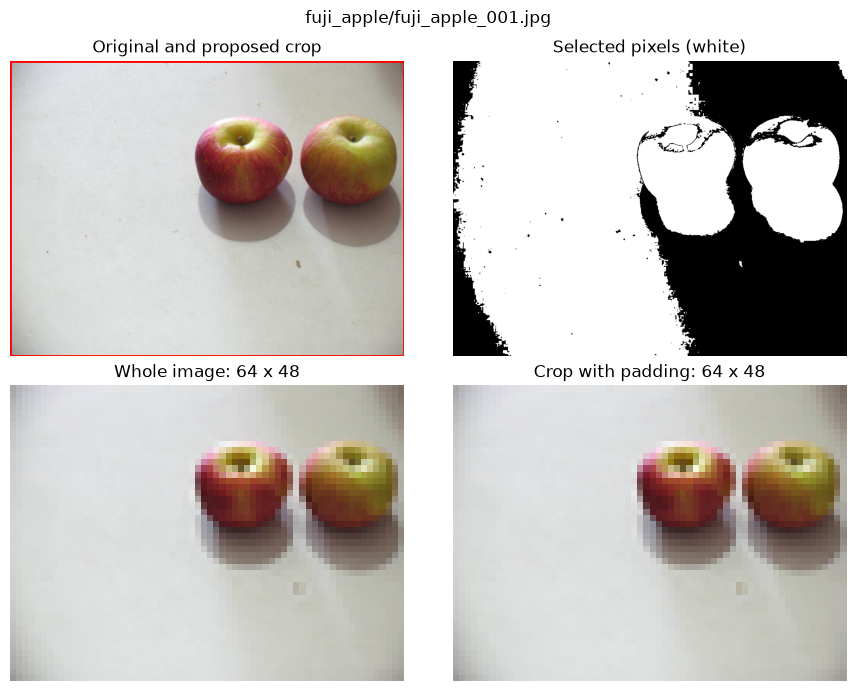

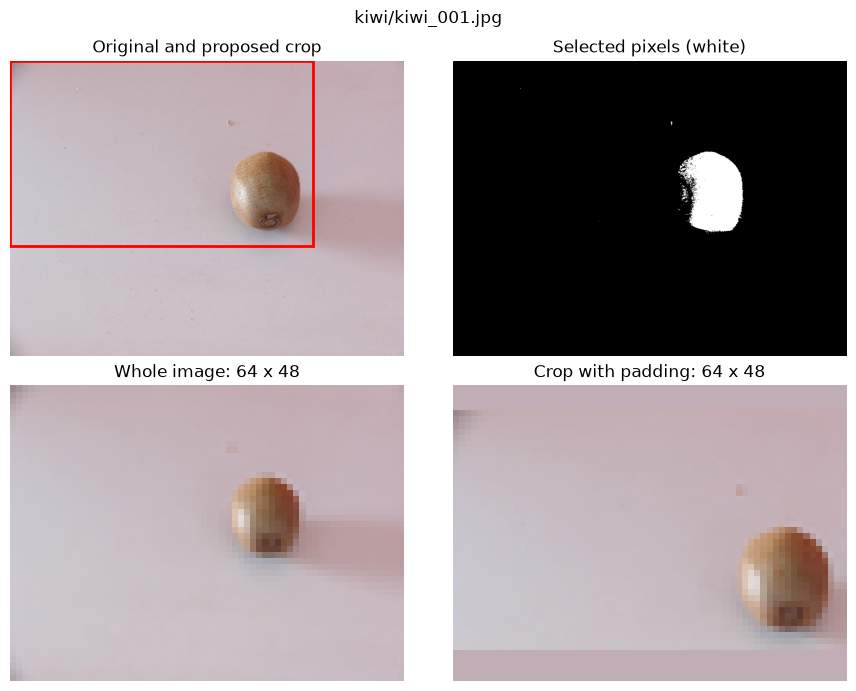

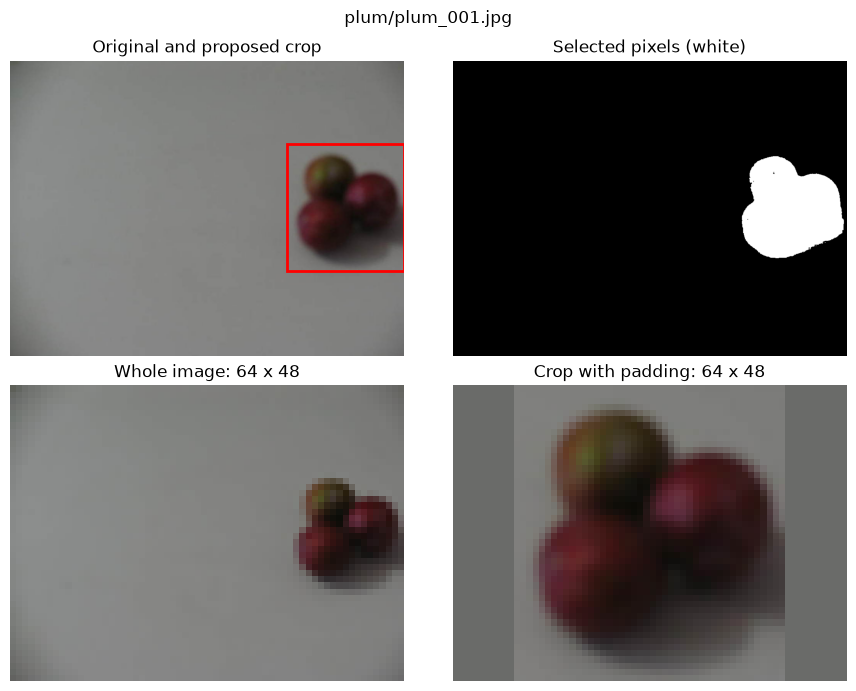

In [11]:
from PIL import ImageOps
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

crop_results = []

for relative_name in crop_example_files:
    file_path = data_folder / relative_name

    with Image.open(file_path) as image:
        original_image = image.convert("RGB")

    crop_box, mask, background_color = estimate_crop_box(
        original_image,
        threshold=background_threshold,
        corner_size=corner_size,
        margin=crop_margin
    )
    cropped_image = original_image.crop(crop_box)

    padding_color = tuple(background_color.astype(int))
    full_input = original_image.resize((64, 48), Image.Resampling.LANCZOS)
    cropped_input = ImageOps.pad(
        cropped_image,
        (64, 48),
        method=Image.Resampling.LANCZOS,
        color=padding_color
    )

    original_area = original_image.width * original_image.height
    crop_area = cropped_image.width * cropped_image.height
    retained_area = crop_area / original_area * 100

    crop_results.append({
        "image": relative_name,
        "crop_box": crop_box,
        "retained_area_percent": retained_area
    })

    print("\nImage:", relative_name)
    print("Estimated background RGB:", background_color)
    print("Crop box:", crop_box)
    print("Crop size (width, height):", cropped_image.size)
    print("Retained rectangle area:", round(retained_area, 1), "%")

    fig, axes = plt.subplots(2, 2, figsize=(9, 7))
    left, top, right, bottom = crop_box

    axes[0, 0].imshow(original_image)
    axes[0, 0].add_patch(Rectangle(
        (left, top), right - left, bottom - top,
        fill=False, edgecolor="red", linewidth=2
    ))
    axes[0, 0].set_title("Original and proposed crop")

    axes[0, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[0, 1].set_title("Selected pixels (white)")

    axes[1, 0].imshow(full_input, interpolation="nearest")
    axes[1, 0].set_title("Whole image: 64 x 48")

    axes[1, 1].imshow(cropped_input, interpolation="nearest")
    axes[1, 1].set_title("Crop with padding: 64 x 48")

    for ax in axes.flat:
        ax.axis("off")

    fig.suptitle(relative_name)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

#### 3.3.1 Cropping Experiment – Findings and Limitations

**Observed results with threshold 50 and a 32-pixel margin**

- **Apple:** The box retained 100% of the original frame. The mask selected a large bright background area as well as the apples, so this method did not reduce the background in this example.
- **Kiwi:** The box retained approximately 48.3% of the original frame. The fruit appears larger at the same input size, but isolated selected pixels near the top-left edge kept the crop wider than the fruit required. Padding is also visible.
- **Plum:** The box retained approximately 12.7% of the original frame. The crop concentrates on the cluster and makes it appear larger at the model input size. The original image already cuts off part of the rightmost fruit. Cropping does not recover that missing content or fix the visible blur.

These percentages describe retained rectangle area, not background-removal accuracy. The mixed results show why this simple method needs wider review before adoption.

Use the saved figures to judge this method. A crop is useful only if it retains the food and produces a useful representation after resizing. A smaller retained area alone does not establish success.

The examples can reveal two different problems: a box that stays nearly as large as the full image because background pixels are selected, and a tight box that might miss food pixels close to the background color.

This method uses a rectangular crop, not full background removal. Background between multiple objects and shadows may remain. The crop is padded to fit a 4:3 input rather than stretched.

**Model evaluation:** We have not measured an accuracy improvement. Once the shared split is available, compare the whole-image baseline with a crop-based baseline using the same split, classifier, and evaluation metrics. Use validation results for decisions and reserve test data for the final comparison. Even a cropping method with no learned parameters can be over-tuned if we repeatedly adjust it after looking at test images.

The original `load_image()` remains the whole-image baseline. Before making cropping a shared option, review a wider sample covering all nine target classes and agree on the rule and failure behavior.